# Grafiken für "neuronale Netze von Hand"

## Boolesche Funktionen

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Enable XKCD mode for a schematic, hand-drawn look (requires relevant font, which may not be present)
plt.xkcd()

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from typing import List, Tuple

# --- Configuration ---
# Define the quadrant vertices (normalized to the plotting limits)
# Q1: (>=0, >=0), Q2: (<0, >=0), Q3: (<0, <0), Q4: (>=0, <0)
QUADRANT_MAP = {
    # (x_min, x_max, y_min, y_max)
    'Q1': (0, 1, 0, 1),
    'Q2': (-1, 0, 0, 1),
    'Q3': (-1, 0, -1, 0),
    'Q4': (0, 1, -1, 0)
}
PLOT_LIMIT = 5

In [3]:
def plot_quadrant_region(
    quadrants_to_fill: List[str],
    title: str,
    label: str,
    color: str = '#006AB3',
    alpha: float = 0.5
) -> None:
    """
    Generates an XKCD-style plot of R^2, filling the specified quadrants.

    Args:
        quadrants_to_fill (List[str]): List of quadrants to fill ('Q1', 'Q2', 'Q3', 'Q4').
        title (str): The plot title (e.g., 'x > 0 AND y > 0').
        label (str): The central label for the region (e.g., 'AND', 'OR').
        color (str): Hex color for the fill.
        alpha (float): Transparency level for the fill.
    """
    # 1. Setup the figure and axes
    plt.xkcd()
    fig, ax = plt.subplots(figsize=(7, 7))

    # 2. Define the plotting area limits
    x_min, x_max = -PLOT_LIMIT, PLOT_LIMIT
    y_min, y_max = -PLOT_LIMIT, PLOT_LIMIT
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect('equal')

    # 3. Plot the axes and position them at (0,0)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_position('zero')
    ax.spines['bottom'].set_position('zero')

    # 4. Fill the specified regions
    # The filling logic is now generalized based on the QUADRANT_MAP
    for q_key in quadrants_to_fill:
        if q_key in QUADRANT_MAP:
            x_norm_start, x_norm_end, y_norm_start, y_norm_end = QUADRANT_MAP[q_key]

            # Calculate actual coordinates using the normalized boundaries
            x_start = x_norm_start * PLOT_LIMIT
            x_end = x_norm_end * PLOT_LIMIT
            y_start = y_norm_start * PLOT_LIMIT
            y_end = y_norm_end * PLOT_LIMIT

            # Define polygon vertices for the quadrant
            q_x = [x_start, x_end, x_end, x_start]
            q_y = [y_start, y_start, y_end, y_end]
            
            ax.fill(q_x, q_y, color, alpha=alpha, edgecolor='none')

    # 5. Add a label for the region
    if quadrants_to_fill:
        # Determine the quadrant for the label placement (use the first filled quadrant)
        label_quadrant = quadrants_to_fill[0]
        
        # Look up the normalized boundaries for the label quadrant
        x_norm_start, x_norm_end, y_norm_start, y_norm_end = QUADRANT_MAP[label_quadrant]
        
        # Calculate the center point of that quadrant
        x_center = (x_norm_start + x_norm_end) / 2 * PLOT_LIMIT
        y_center = (y_norm_start + y_norm_end) / 2 * PLOT_LIMIT
        
        # Place the label
        ax.text(x_center, y_center, label, fontsize=24, ha='center', va='center')

    # 6. Labels and appearance
    ax.set_title(title)
    #ax.set_xlabel(r'$x$', fontsize=16, ha='right', x=1.05)
    #ax.set_ylabel(r'$y$', fontsize=16, ha='right', y=1.05, rotation=0)

    # Set ticks only at the origin to keep it schematic
    ax.set_xticks([0])
    ax.set_yticks([0])
    ax.set_xticklabels([r'0 '], ha='right', va='top')
    ax.set_yticklabels([], ha='right', va='top')

    # Remove ticks on the axes themselves
    ax.tick_params(axis='both', which='both', length=0)

    plt.show()

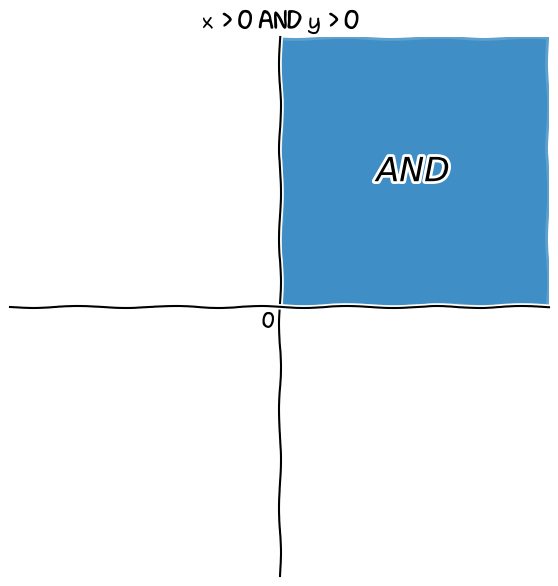

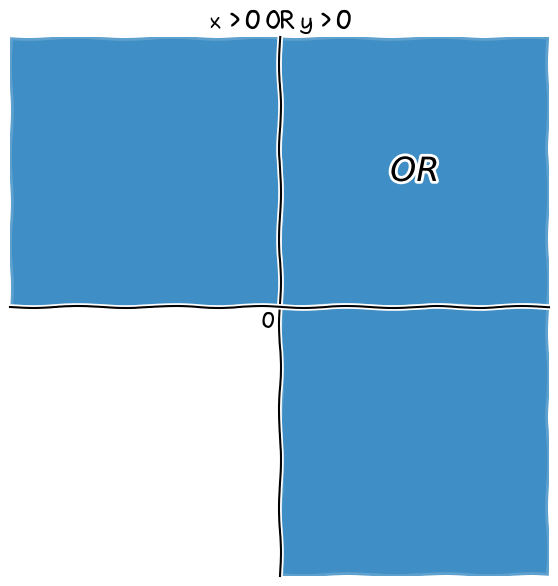

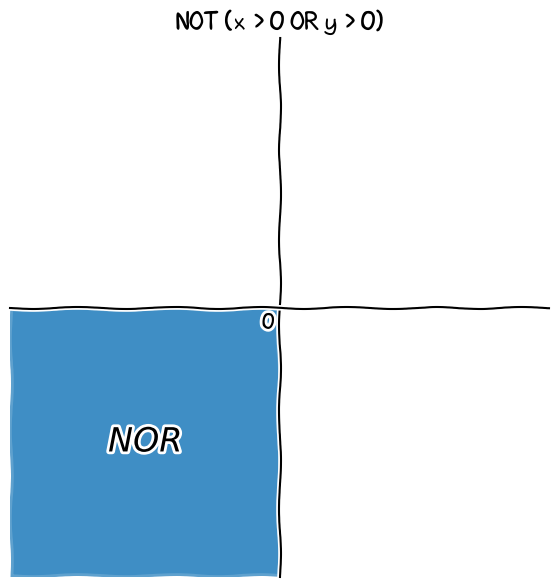

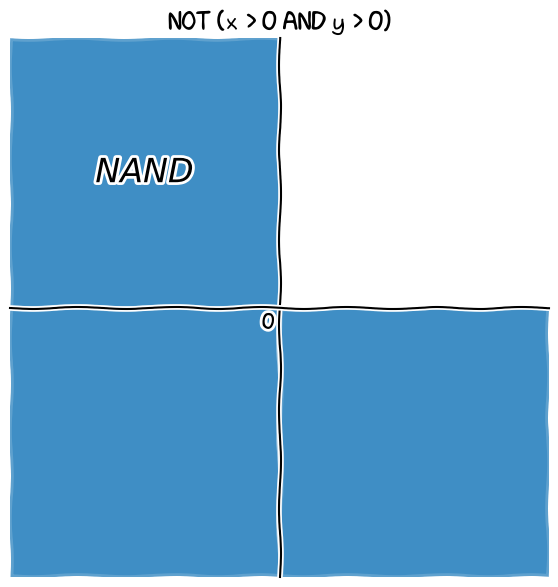

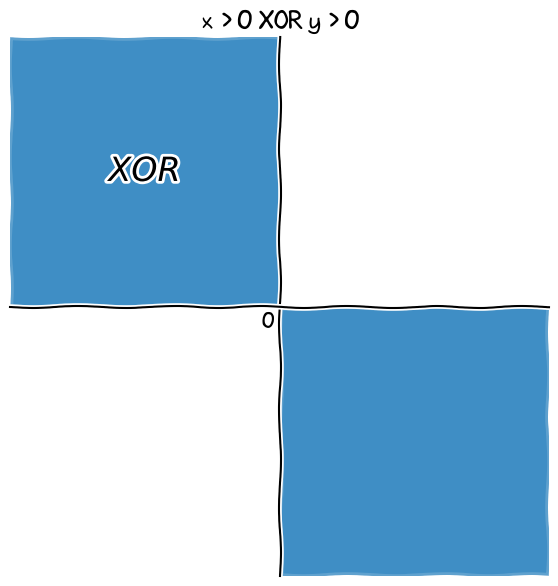

In [4]:
plot_quadrant_region(
    quadrants_to_fill=['Q1'],
    title='x > 0 AND y > 0',
    label=r'$AND$'
)

plot_quadrant_region(
    quadrants_to_fill=['Q1', 'Q2', 'Q4'],
    title='x > 0 OR y > 0',
    label=r'$OR$'
)

plot_quadrant_region(
    quadrants_to_fill=['Q3'],
    title='NOT (x > 0 OR y > 0)',
    label=r'$NOR$',
)

plot_quadrant_region(
    quadrants_to_fill=['Q2', 'Q3', 'Q4'],
    title='NOT (x > 0 AND y > 0)',
    label=r'$NAND$',
)

plot_quadrant_region(
    quadrants_to_fill=['Q2', 'Q4'],
    title='x > 0 XOR y > 0',
    label=r'$XOR$',
)

## Einfache Arithmetik

$$f(x,y) := x^3 + xy^2 - 3y$$

Einfachere Probleme, die wir nicht lösen können:

$$f(x,y) := xy$$
$$f(x) := x^2$$

Ansatz für $x\mapsto x^2$: Interpolation, etwa auf $[-3,3]$

In [5]:
# 1. Define the domain for the square function
x_domain = np.linspace(-4, 4, 400)
y_square = x_domain**2

# 2. Define integer points for the piecewise linear approximation
x_integer_points = np.arange(-3, 4, 1) # -3, -2, -1, 0, 1, 2, 3
y_integer_points = x_integer_points**2 # 9, 4, 1, 0, 1, 4, 9

# 3. Create the piecewise linear approximation
# This involves connecting the integer points with straight lines.
# We'll use these integer points directly for plotting the linear segments.
x_linear_approx = x_integer_points
y_linear_approx = y_integer_points

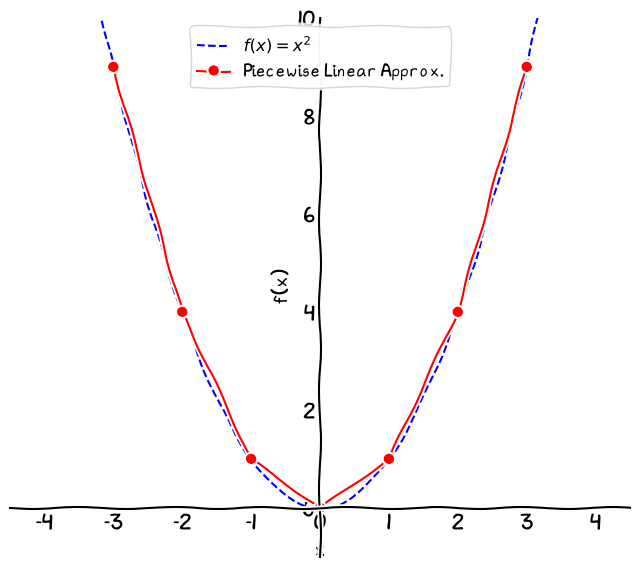

In [6]:
# 4. Setup the figure and axes
fig, ax = plt.subplots(figsize=(8, 7))

# 5. Set limits and labels
ax.set_xlim(-4.5, 4.5)
ax.set_ylim(-1, 10) # Adjust y-limit to accommodate up to 3^2 = 9
ax.set_xlabel('x', fontsize=14)
ax.set_ylabel('f(x)', fontsize=14)
#ax.set_title('Square Function and Piecewise Linear Approximation')

# 6. Plot the square function (the smooth curve)
ax.plot(x_domain, y_square, label=r'$f(x) = x^2$', color='blue', linestyle='--', linewidth=1.5)

# 7. Plot the piecewise linear approximation
ax.plot(x_linear_approx, y_linear_approx, label='Piecewise Linear Approx.', color='red', marker='o', linestyle='-', linewidth=1.5, markersize=6)

# 8. Add grid and legend for clarity
#ax.grid(True, linestyle=':', alpha=0.7)
ax.legend(fontsize=12)

# 9. Customize XKCD style axes
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_position(('data', 0))
ax.spines['bottom'].set_position(('data', 0))

# Remove ticks on axes for cleaner XKCD look, keep labels on the major points
ax.set_xticks(np.arange(-4, 5, 1))
ax.set_yticks(np.arange(0, 11, 2)) # Adjust y-ticks for better visualization of squares
ax.tick_params(axis='x', which='both', length=0)
ax.tick_params(axis='y', which='both', length=0)

# 10. Show plot
plt.show()

Wir strukturieren die Berechnung der stückweisen Approximation so:
$$Q(x) := -5x - 6 + 2 \sum_{k=-2}^{2} ReLU(x - k)$$
Beispiele:
$$Q(2) = -10 - 6 + 2(ReLU(2+2) + ReLU(2+1) + ReLU(2-0) + ReLU(2-1) + ReLU(2-2))$$
$$ = -16 + 2( 4 + 3 + 2 + 1 + 0 ) = 20-16 = 4$$
$$Q(-2) = 10 - 6 + 2(ReLU(-2+2) + ReLU(-2+1) + ReLU(-2-0) + ReLU(-2-1) + ReLU(-2-2))$$
$$ = 4 + 2( 0 + 0 + 0 + 0 + 0 ) = 4 + 0 = 4$$

Wir wollen zur Eingabe $x$ also die $5$ Terme $a_k := ReLU(x - k)$ berechnen,
das ist die erste Schicht mit $5$ Neuronen mit jeweils Gewicht 1 und Bias $k$ für $k \in \{-2,-1,0,1,2\}$ und ReLU-Aktivierung.

Die zweite Schicht soll $\sum 2 a_k$ berechnen, also ein einzelnes Neuron mit Gewichtsvektor $(2,2,2,2,2)$. Für den Summanden $-5x-6$ verwenden wir in der ersten Schicht noch ein separates Neuron mit Gewicht $-5$ und Bias $-6$ und Aktivierung $id$, der nimmt an der Summe in der zweiten Schicht teil, wenn wir das Gewicht auf $(1,2,2,2,2,2)$ setzen und das einzelne Neuron als "erstes" setzen.

Das Konstruktionsprinzip: $-5x - 6$ ist die beste lineare Näherung für $x=-3$ und die anderen Terme korrigieren diese Funktion für $x \geq -2$ bzw. $x \geq -1$ usw.

Alternativ kann man die Symmetrie von $x^2$ nutzen, und die Interpolation nur auf $[0,3]$ nutzen, und zuvor die Abbildung $x \mapsto |x|$ schalten:
$$|x| = ReLU(x) + ReLU(-x)$$
Das ist das neuronale Netz mit zwei Neuronen in der ersten Schicht, Gewichte $1$ und $-1$ und ReLU-Aktivierung, und ein Neuron mit Gewichtsvektor $(1,1)$ in der zweiten Schicht.

Damit wird die Interpolation einfacher:
$$P(x) := |x| + 2ReLU(|x|-1) + 2ReLU(|x|-2)$$
Wir brauchen dazu also "nur" noch 3 Neuronen in der ersten Schicht und eins in der zweiten. Wenn wir aber das "ganze" mitzählen, also auch unsere Betragsfunktion, sieht es schon anders aus - vier versteckte Schichten.

In der Praxis könnten wir auch direkt PyTorch bitten, $x^2$ zu berechnen, auch wenn wir damit den Rahmen des "simple feedforward multilayer perceptron" verlassen. Der Nachteil ist, dass wir im Allgemeinen nicht wissen, ob wir $x^2$ berechnen müssen, um eine Funktion $f$ gut zu approximieren.

Wenn man aber $x^2$ berechnen kann, dann auch beliebige Produkte über die Polarisationsidentität:
$$\dfrac{(x+y)^2 - (x-y)^2}{4} = \dfrac{x^2 +2xy + y^2 - x^2 + 2xy - y^2}{4} = xy$$
Für eine Approximation $Q$ der Quadratfunktion können wir also mit
$$MUL(x,y) := \frac{1}{4} Q(x+y) - \frac{1}{4} Q(x-y)$$
die Rechnung auf $Q$ und Skalarprodukte zurückführen.

Mit $MUL$ haben wir dann auch durch Verkettung die Möglichkeit, beliebige Polynome in beliebig vielen Variablen zu approximieren.

In der Praxis wollen wir also vielleicht das neuronale Netz so strukturieren, dass auch $x^2$ (exakt) berechnet wird, statt interpoliert, oder allgemeiner $xy$ (Stichwort Gates).

Was aber, wenn wir z.B. $\sin(x)$ berechnen wollen?

Das können wir direkt auf der GPU rechnen - dort ist eine Wertetabelle hinterlegt und über fuse-multiply-add lässt sich leicht eine quadratische Interpolation dieser Werte in einem einzigen Taktzyklus durchführen. Das ist eine sehr schnelle, aber relativ schlechte Interpolation; PyTorch verwendet diese mit CUDA automatisch, wenn man mit 16-bit Präzision arbeitet; ansonsten wird eine teurere, präzisere Version verwendet.